In [1]:
import gzip
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 6.5,
    "axes.linewidth": 0.7,
    "lines.linewidth": 1.0, "lines.markersize": 3.0,
    "lines.markeredgewidth": 0.5,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "xtick.major.pad": 2.0, "ytick.major.pad": 2.0,
    "axes.labelpad": 2.5,
})

def to_complex(s):
    return np.array([complex(v.replace("i", "j")) for v in s])

In [2]:
Ein = 1.0                 

with gzip.open("../data/Field3.txt.gz", "rt", encoding="utf-8") as f:
    raw = np.array([l.split() for l in f if not l.startswith("%")])

zs, xs = raw[:, 0].astype(float), raw[:, 1].astype(float)   # z along surface, x normal
Ey, Hz = to_complex(raw[:, 4]), to_complex(raw[:, 5])       # file Ez -> E_y, file Hx -> H_z

uz, ux = np.unique(zs), np.unique(xs)                      

def to_grid(v):                                           
    G = np.full((uz.size, ux.size), np.nan, dtype=v.dtype)
    G[np.searchsorted(uz, zs), np.searchsorted(ux, xs)] = v
    return G

Ey, Hz = to_grid(Ey), to_grid(Hz)

iz = np.flatnonzero(np.isfinite(Ey).any(1))                 
ix = np.flatnonzero(np.isfinite(Ey).any(0))
sl = (slice(iz[0], iz[-1] + 1), slice(ix[0], ix[-1] + 1))
Ey, Hz, uz, ux = Ey[sl], Hz[sl], uz[sl[0]], ux[sl[1]]

A  = np.abs(Ey) / Ein                  
jz = np.argmin(np.abs(uz))             # column z = 0
jx = np.argmin(np.abs(ux))             # row    x = 0

kg  = 1.7205                           # k_g = 1.7205e6 1/m -> rad/mkm
Lam = 2 * np.pi / kg                   # 3.652 mkm = grating period

We suppose that

$$|E_y(z,x)| = b(x) + a_1(x)\,\cos\!\big(k_gz\big),$$

and perform fitting

In [3]:
B = np.column_stack([np.ones_like(uz), np.cos(kg * uz)])
c = np.linalg.lstsq(B, A, rcond=None)[0]                 

resid = np.sqrt(np.mean((B @ c - A) ** 2, axis=0))       # residual of the fit
a1 = np.abs(c[1])                                        # modulation amplitude
b0 = c[0, jx]                                            # background at x = 0

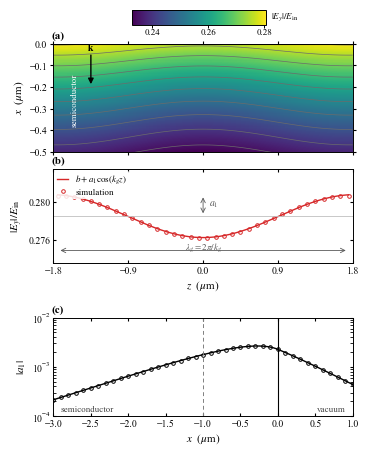

In [4]:
MM = 1 / 25.4
W_MM = 90.0
L_MM, R_MM = 11.5, 2.5

BOT, C_LAB, C_H, GAP2 = 1.5, 9.5, 25.0, 4.3
B_LAB, B_H, GAP1, A_H, CBAR = 9.5, 24.0, 4.3, 27.5, 9.6
H_MM = BOT + C_LAB + C_H + GAP2 + B_LAB + B_H + GAP1 + A_H + CBAR

c_bot = BOT + C_LAB
b_bot = c_bot + C_H + GAP2 + B_LAB
a_bot = b_bot + B_H + GAP1
Wp_MM = W_MM - L_MM - R_MM

def rect(x, y, w, h):
    return [x / W_MM, y / H_MM, w / W_MM, h / H_MM]

fig = plt.figure(figsize=(W_MM * MM, H_MM * MM))

ax = fig.add_axes(rect(L_MM, a_bot, Wp_MM, A_H))
axb = fig.add_axes(rect(L_MM, b_bot, Wp_MM, B_H))
axc = fig.add_axes(rect(L_MM, c_bot, Wp_MM, C_H))

def plabel(ax, s):
    ax.text(-0.005, 1.03, s, transform=ax.transAxes, ha="left",
            va="bottom", weight="bold", fontsize=8)

XMIN, XMAX = -0.5, 0.0
win = (ux >= XMIN) & (ux <= XMAX)
vmin, vmax = A[:, win].min(), A[:, win].max()

uz_e = np.r_[uz[0] - 0.05, uz, uz[-1] + 0.05]
A_e = np.concatenate((A[:1], A, A[-1:]), axis=0)

m = ax.pcolormesh(
    uz_e, ux, A_e.T, cmap="viridis",
    vmin=vmin, vmax=vmax, shading="nearest", rasterized=True
)

levels = np.arange(np.ceil(vmin / 0.005) * 0.005, vmax + 1e-9, 0.005)
ax.contour(uz_e, ux, A_e.T, levels=levels, colors=(0.42, 0.42, 0.42),
           linewidths=0.5, zorder=2)

cax = fig.add_axes(rect(L_MM + 20.0, a_bot + A_H + 4.8, 34.0, 3.8))
cbar = fig.colorbar(m, cax=cax, orientation="horizontal")
cbar.set_ticks(np.arange(np.ceil(vmin / 0.02) * 0.02, vmax + 1e-9, 0.02))
cbar.ax.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%.2f"))
cbar.ax.tick_params(labelsize=6.5, length=2.0, width=0.7, pad=1.2, direction='out')
cbar.ax.text(1.04, 0.5, r"$|E_y|/E_{\rm in}$",
             transform=cbar.ax.transAxes, ha="left", va="center",
             fontsize=6.5)

ax.axhline(0, color="k", lw=0.8)
ax.text(-1.55, -0.26, "semiconductor", color="w", rotation=90,
        ha="center", va="center", fontsize=6.5)
ax.annotate("", xy=(-1.35, -0.20), xytext=(-1.35, -0.04),
            arrowprops=dict(arrowstyle="-|>", lw=1.0, color="k"), zorder=6)
ax.text(-1.35, -0.04, r"$\mathbf{k}$", color="k",
        ha="center", va="bottom", fontsize=7)

ax.set(xlim=(uz.min() - 0.05, uz.max() + 0.05),
       ylim=(XMIN, XMAX),
       ylabel=r"$x$  ($\mu$m)")
ax.set_xticks([-1.8, -0.9, 0, 0.9, 1.8])
ax.set_yticks([-0.5, -0.4, -0.3, -0.2, -0.1, 0])
ax.tick_params(labelbottom=False, direction='out')
ax.set_xlabel("")
plabel(ax, "(a)")


stepz = max(1, int(round(0.1 / (uz[1] - uz[0]))))
a = a1[jx]

axb.plot(uz, B @ c[:, jx], "-", color="C3", lw=1.0,
         label=r"$b + a_1\cos(k_gz)$")
axb.plot(uz[::stepz], A[::stepz, jx], "o", mfc="none",
         ms=2.6, mew=0.7, color="C3", label="simulation")
axb.axhline(b0, color="0.75", lw=0.6)

axb.annotate("", xy=(0, b0), xytext=(0, b0 + a),
             arrowprops=dict(arrowstyle="<->", lw=0.6, color="0.35"))
axb.text(0.07, b0 + 0.55 * a, r"$a_1$", ha="left", va="center",
         color="0.35", fontsize=7)

axb.annotate("", xy=(uz.min(), b0 - 1.6 * a),
             xytext=(uz.max(), b0 - 1.6 * a),
             arrowprops=dict(arrowstyle="<->", lw=0.6, color="0.35"))
axb.text(0, b0 - 1.14 * a, r"$\lambda_g = 2\pi/k_g$",
         ha="center", va="top", color="0.35", fontsize=6.5)

axb.set(xlim=(uz.min() - 0.05, uz.max() + 0.05),
        ylim=(b0 - 2.2 * a, b0 + 2.2 * a),
        xlabel=r"$z$  ($\mu$m)", ylabel=r"$|E_y|/E_{\rm in}$")
axb.ticklabel_format(axis="y", useOffset=False)
axb.yaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=3))
axb.set_xticks([-1.8, -0.9, 0, 0.9, 1.8])
axb.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%.1f"))
axb.legend(loc="upper left", bbox_to_anchor=(0.0, 0.99),
           handlelength=1.2, labelspacing=0.2, borderpad=0.25,
           borderaxespad=0.15, frameon=True, facecolor="w",
           edgecolor="none", framealpha=0.85)
axb.sharex(ax)
plabel(axb, "(b)")

stepx = max(1, int(round(0.1 / (ux[1] - ux[0]))))

axc.semilogy(ux, a1, "-", color="k", lw=1.0)
axc.semilogy(ux[::stepx], a1[::stepx], "o", mfc="none",
             ms=2.6, mew=0.7, color="k")
axc.axvline(0, color="k", lw=0.8)
axc.axvline(-1.0, color="0.5", lw=0.7, ls=(0, (4, 3)))

axc.set(xlim=(ux.min(), ux.max()), xlabel=r"$x$  ($\mu$m)",
        ylabel=r"$|a_1|$")
axc.set_yticks([1e-4, 1e-3, 1e-2])
axc.text(0.9, 1.2e-4, "vacuum", fontsize=6.5,
         color="0.25", ha="right")
axc.text(-2.9, 1.2e-4, "semiconductor", fontsize=6.5,
         color="0.25", ha="left")
plabel(axc, "(c)")

fig.savefig("../Figs/fig_field_en9.png", dpi=600)
fig.savefig("../Figs/fig_field_en9.pdf")
plt.show()

**Figure 1.** Field above the grating, normalised to the incident amplitude
$E_{\rm in} = 1$. **(a)** Map of the out-of-plane field $|E_y|/E_{\rm in}$ over one
grating period $\Lambda = 2\pi/k_g$ mkm along the surface $z$, as a function of the
normal coordinate $x$ (the neighbourhood of the interface in the
semiconductor); solid line — interface at $x = 0$. **(b)**
$|E_y|/E_{\rm in}$ along one grating period at the interface $x = 0$: symbols are the
calculated values using FEM, the curve is the harmonic fit
$|E_y| = b + a_1\cos(k_gz)$. The modulation period is the grating period
$\Lambda$, and the double arrow marks its amplitude $a_1/E_{\rm in}$. **(c)** Modulation amplitude $a_1/E_{\rm in}$ versus
depth $x$ (symbols — the calculated values uding FEM).